# PromptShield: CNN tuning with training folds
Work through the numbered steps from top to bottom. Like `promptshield_analysis.ipynb`,
each section explains the next calculation before running it.

**Part A (steps 1–8):** inspect settings, data, folds, and the model input.
**Part B (steps 9–12):** compare CNNs and inspect the fold results.
**Part C (steps 13–14):** retrain the selected configuration and save the handoff.
You can stop after any part and continue later.

Labels: **0 = benign**, **1 = injection**. Preprocessing stays fixed: lowercase words
and punctuation, up to 20,000 vocabulary entries, and the first 1,024 tokens.
We add no cleaning or augmentation. The official validation and test files are
not opened anywhere in this notebook.

Start in **smoke mode**: one configuration, one held-out fold, one epoch, and a small
grouped training sample. Those scores only verify the workflow. After that, set
`SMOKE_MODE = False` and rerun to perform the full eight-configuration search.

The saved full-run outputs are retained from the original experiment. The notebooks, shared code, and results now live together in `cnn/`; the shared original dataset remains in `../data/`. Restart the kernel before executing the relocated notebooks.

## 1. Install notebook packages
Viewing the saved tables and plots requires no installation or rerun.
To execute cells, install the notebook dependencies into your chosen Python
environment. From the **repository root**, run this terminal command:

```powershell
uv pip install --python .venv/Scripts/python.exe -r cnn/requirements-notebooks.txt
```

If using the existing AMD environment, replace `.venv/Scripts/python.exe`
with `gpu_test/.venv/Scripts/python.exe`. Select that interpreter as the
notebook kernel. These notebook dependencies do not request a different
PyTorch build. Both the repository root and `cnn/` are supported as working directories.

In [39]:
# Notebook dependencies are installed with the terminal command above.

## 2. Imports
Shared model and training functions live in `cnn_experiments.py`. Importing it does not start training.

In [40]:
from dataclasses import asdict
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# VS Code may start the kernel at the repository root or in cnn/.
candidates = (Path.cwd(), Path.cwd() / "cnn")
CNN_DIR = next((folder.resolve() for folder in candidates
                if (folder / "cnn_experiments.py").is_file()), None)
if CNN_DIR is None:
    raise RuntimeError("Open this notebook from the repository root or cnn/ folder")
if str(CNN_DIR) not in sys.path:
    sys.path.insert(0, str(CNN_DIR))
import cnn_experiments as exp

ROOT = exp.ROOT
DATA_DIR = ROOT / "data"
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
pd.set_option("display.max_columns", 24)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

Python: c:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\gpu_test\.venv\Scripts\python.exe
PyTorch: 2.14.0+rocm10.1.0


## 3. Choose the run mode and device
The full search uses 8 configurations × 5 folds = **40 independent training runs**,
followed by one final retraining. GPU trials run sequentially. The actual device
and package versions are stored with the experiment.

Completed matching folds can resume. Changes to code, data, settings, or runtime
require a new experiment folder so old results are not mixed with new ones.

In [41]:
SMOKE_MODE = False  # First verify the workflow; set False for all 40 fold runs.
RUN_NAME = "gpu_focused_v1"  # Choose a new name when changing code or settings.
DEVICE_REQUEST = "cuda:0"  # "auto", "cpu", or "cuda:0" (also used by ROCm).
torch.set_num_threads(4)

DEVICE = exp.resolve_device(DEVICE_REQUEST)
RUN_DIR = exp.ARTIFACTS_DIR / (
    f"smoke_{RUN_NAME}" if SMOKE_MODE else RUN_NAME
)
print("Mode:", "SMOKE: demonstration only" if SMOKE_MODE else "FULL SEARCH")
print("Experiment folder:", RUN_DIR)
display(pd.Series(exp.runtime_info(DEVICE), name="Runtime"))

Mode: FULL SEARCH
Experiment folder: C:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\artifacts\cnn_experiments\gpu_focused_v1


python                     3.14.4
torch           2.14.0+rocm10.1.0
numpy                       2.5.4
scikit_learn                1.9.1
device                     cuda:0
device_name     Radeon RX 5500 XT
hip                    7.16.26385
cuda                         None
cpu_threads                     4
Name: Runtime, dtype: object

## 4. Read training data
Read only `train.json`. Smoke mode samples complete duplicate groups and keeps both
classes approximately balanced. Original row indices are retained for saved predictions.
Prompt strings are data and are never executed.

In [42]:
all_training = exp.read_split(DATA_DIR, "train")
rows = exp.smoke_subset(all_training, limit=160, seed=42) if SMOKE_MODE else all_training
settings = exp.SearchSettings(smoke=SMOKE_MODE, max_epochs=1 if SMOKE_MODE else 10)
print(f"Official training rows: {len(all_training):,}")
print(f"Rows used in this run: {len(rows):,}")
frame = pd.DataFrame(rows)
display(frame["label"].value_counts().rename(index={0: "benign", 1: "injection"}).to_frame("rows"))
with pd.option_context("display.max_colwidth", 140):
    display(frame.head())

Official training rows: 18,909
Rows used in this run: 18,909


,rows
label,
benign,9457
injection,9452


,row_index,prompt,label
0,0,"\n\nWhat are the components that make a successful person? After your response, please explicitly add a postscript starting with P.P.S Y...",0
1,1,\nWhat actions can individuals take to reduce their carbon footprint and support environmental conservation efforts in Australasia?\n\n,0
2,2,\n\nTransform the given sentence into a declarative sentence.\n\n\nShould we go now?\n\n,0
3,3,"\n\n\nWrite an engaging and interesting short story about the below [sentence]. Write it in second person, and make sure to use good gra...",1
4,4,\n\nWrite a funny poem for kids about a product that you would like to sell. The poem should have exactly 6 stanzas. Separated the stanz...,0


## 5. Review the eight configurations
Configuration 1 uses the current CNN architecture and optimizer settings under the
new fold protocol. Configurations 2–4 progressively change learning rate, dropout,
and weight decay. Configurations 5–8 branch from configuration 4.

Every model learns its embeddings from scratch. Embedding size remains 64 and batch
size remains 32. A wider kernel scans more neighboring tokens; stacked convolutions
increase the number of successive convolution layers.

In [43]:
configurations = exp.default_configurations()
display(pd.DataFrame([asdict(config) for config in configurations]).set_index("config_id"))
display(pd.Series(exp.PREPROCESSING, name="Fixed preprocessing"))
print("Smoke mode runs configuration 1 only." if SMOKE_MODE else "All eight configurations will run.")

,name,embedding_dim,num_filters,kernel_size,depth,dropout,learning_rate,weight_decay,batch_size
config_id,,,,,,,,,
cnn01,Current CNN recipe,64,256,3,1,0.0,0.005,0.0000,32
cnn02,Lower learning rate,64,256,3,1,0.0,0.001,0.0000,32
cnn03,Dropout,64,256,3,1,0.3,0.001,0.0000,32
cnn04,Weight decay,64,256,3,1,0.3,0.001,0.0001,32
cnn05,128 filters,64,128,3,1,0.3,0.001,0.0001,32
cnn06,Kernel size 5,64,256,5,1,0.3,0.001,0.0001,32
cnn07,Two convolutions,64,256,3,2,0.3,0.001,0.0001,32
cnn08,Three convolutions,64,256,3,3,0.3,0.001,0.0001,32


tokenizer              lowercase_regex_words_and_punctuation_v1
max_vocabulary_size                                       20000
max_sequence_length                                        1024
padding_id                                                    0
unknown_id                                                    1
Name: Fixed preprocessing, dtype: object

All eight configurations will run.


## 6. Identify duplicate groups
Grouping uses the same case-and-whitespace normalization as the original analysis.
We use this key only for splitting: the original prompt text still goes to the tokenizer.
Matching normalized prompts must stay on the same side of every split.

This detects case and whitespace duplicates, not shared templates or paraphrases.

In [44]:
frame["group"] = [exp.group_id(row["prompt"]) for row in rows]
group_sizes = frame.groupby("group").size()
print("Unique groups:", len(group_sizes))
print("Extra duplicate rows:", int((group_sizes - 1).sum()))
print("Groups with conflicting labels:", int((frame.groupby("group")["label"].nunique() > 1).sum()))

Unique groups: 18841
Extra duplicate rows: 68
Groups with conflicting labels: 0


## 7. Build and inspect the training folds
Five-fold cross-validation holds out approximately one fifth of training data in turn.
We train a fresh model for each configuration and fold; weights are never carried
from one fold into the next.

Inside the remaining four fifths, reserve approximately 10% for **early stopping**.
This smaller split chooses the training epoch. The outer held-out fold then scores
that chosen checkpoint. The official validation split remains separate.

`StratifiedGroupKFold` keeps normalized groups together and approximates class balance.
See the [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

In [45]:
folds = exp.make_folds(rows, settings)
fold_counts = []
for fold in folds:
    for role in ("train", "early_stopping", "heldout"):
        labels = [rows[index]["label"] for index in fold[role]]
        fold_counts.append({"fold": fold["fold"], "role": role, "rows": len(labels),
                            "benign": labels.count(0), "injection": labels.count(1)})
display(pd.DataFrame(fold_counts))
print("Group separation and complete held-out coverage passed.")
print("Only fold 1 is executed in smoke mode; all five are shown for inspection.")

,fold,role,rows,benign,injection
0,1,train,13614,6809,6805
1,1,early_stopping,1513,757,756
2,1,heldout,3782,1891,1891
3,2,train,13614,6808,6806
4,2,early_stopping,1513,757,756
5,2,heldout,3782,1892,1890
6,3,train,13614,6809,6805
7,3,early_stopping,1513,757,756
8,3,heldout,3782,1891,1891
9,4,train,13614,6808,6806


Group separation and complete held-out coverage passed.
Only fold 1 is executed in smoke mode; all five are shown for inspection.


## 8. Inspect a fold vocabulary and encoded inputs
A fold's vocabulary is fitted only on examples used to update weights. Words that
appear only in early-stopping or held-out examples become `<UNK>`.

The vocabulary limit includes `<PAD>` (ID 0) and `<UNK>` (ID 1). Each prompt is
truncated to its first 1,024 tokens or padded with zeros, as in the existing CNN.

In [46]:
first_fold = folds[0]
fit_rows = [rows[index] for index in first_fold["train"]]
preview_vocabulary = exp.build_vocabulary([row["prompt"] for row in fit_rows])
preview_texts = [row["prompt"] for row in fit_rows[:2]]
preview_inputs = exp.encode_texts(preview_texts, preview_vocabulary)
print("Fold vocabulary entries:", len(preview_vocabulary))
print("Encoded input shape:", tuple(preview_inputs.shape))
print("First 20 tokens:", exp.tokenize(preview_texts[0])[:20])
print("First 20 token IDs:", preview_inputs[0, :20].tolist())

Fold vocabulary entries: 20000
Encoded input shape: (2, 1024)
First 20 tokens: ['what', 'are', 'the', 'components', 'that', 'make', 'a', 'successful', 'person', '?', 'after', 'your', 'response', ',', 'please', 'explicitly', 'add', 'a', 'postscript', 'starting']
First 20 token IDs: [88, 23, 4, 2125, 20, 76, 7, 938, 170, 39, 202, 36, 159, 5, 122, 4310, 284, 7, 4947, 1078]


## 9. Inspect the CNN before training
The model applies **embedding → convolution(s) + ReLU → global max pooling →
dropout → one output logit**. Binary cross-entropy applies the sigmoid internally.

Every convolution masks windows containing padding. Inputs shorter than a complete
receptive field have zero pooled features and a finite classifier-bias prediction.
This shape preview uses random weights and is not a model evaluation.

In [47]:
exp.seed_everything(42)
preview_model = exp.ExperimentCNN(preview_vocabulary, configurations[0]).eval()
print(preview_model)
print("Parameter count:", sum(parameter.numel() for parameter in preview_model.parameters()))
with torch.inference_mode():
    print("Output logit shape:", tuple(preview_model(preview_inputs).shape))
del preview_model

ExperimentCNN(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (convolutions): ModuleList(
    (0): Conv1d(64, 256, kernel_size=(3,), stride=(1,))
  )
  (dropout): Dropout(p=0.0, inplace=False)
  (classifier): Linear(in_features=256, out_features=1, bias=True)
)
Parameter count: 1329665
Output logit shape: (2,)


## 10. Run cross-validation
Each run uses Adam and binary cross-entropy, for at most 10 epochs, stopping after
two epochs without lower early-stopping loss. Restore the best epoch, then evaluate
the outer held-out fold at threshold **0.5**. Smoke mode uses one epoch.

This cell runs the fold search only. It saves each completed fold immediately, so
rerunning the cell resumes matching completed work. Final retraining is a later step.

If a completed leaderboard already exists, this cell loads the saved results without training. This also supports the relocated historical run. Choose a new `RUN_NAME` when you intend to train a new experiment.

In [48]:
if (RUN_DIR / "leaderboard.json").is_file():
    search = exp.load_search(RUN_DIR, require_selected=False)
    print("Loaded the completed search; no fold training needed.")
    print("Choose a new RUN_NAME to train a new experiment.")
else:
    search = exp.run_search(
        RUN_DIR, DATA_DIR, settings=settings, configurations=configurations,
        device=DEVICE, refit=False,
    )
print("Completed fold runs:", len(search["fold_results"]))

Training cnn01 (Current CNN recipe), fold 1/5 on cuda:0
  epoch 1: train loss 0.1884, early-stop loss 0.1512
  epoch 2: train loss 0.0699, early-stop loss 0.1445
  epoch 3: train loss 0.0378, early-stop loss 0.1974
  epoch 4: train loss 0.0276, early-stop loss 0.1955
Training cnn01 (Current CNN recipe), fold 2/5 on cuda:0
  epoch 1: train loss 0.1885, early-stop loss 0.2765
  epoch 2: train loss 0.0616, early-stop loss 0.0824
  epoch 3: train loss 0.0322, early-stop loss 0.2134
  epoch 4: train loss 0.0442, early-stop loss 0.1595
Training cnn01 (Current CNN recipe), fold 3/5 on cuda:0
  epoch 1: train loss 0.1813, early-stop loss 0.1049
  epoch 2: train loss 0.0694, early-stop loss 0.1140
  epoch 3: train loss 0.0495, early-stop loss 0.4491
Training cnn01 (Current CNN recipe), fold 4/5 on cuda:0
  epoch 1: train loss 0.1830, early-stop loss 0.1315
  epoch 2: train loss 0.0827, early-stop loss 0.1020
  epoch 3: train loss 0.0535, early-stop loss 0.1351
  epoch 4: train loss 0.0392, earl

## 11. Compare configurations
Rank by **highest mean macro F1** across held-out folds. Break ties by lower macro-F1
standard deviation, then fewer parameters. Other metrics expose precision, recall,
false-alarm, and ranking tradeoffs. Standard deviations are sample standard deviations.

Parameter count is the fold mean because training-only vocabularies can differ in size.
The table describes within-training performance, not unfamiliar-source generalization.
A smoke table contains one demonstration run and cannot establish the best CNN.

,config_id,name,folds,macro_f1_mean,macro_f1_std,injection_precision_mean,injection_recall_mean,injection_f1_mean,false_positive_rate_mean,roc_auc_mean,average_precision_mean,parameter_count,training_seconds
0,cnn06,Kernel size 5,5,0.980326,0.002634,0.981287,0.979370,0.980303,0.018717,0.998090,0.998189,1362433.0,566.734449
1,cnn04,Weight decay,5,0.978581,0.001412,0.979249,0.977888,0.978561,0.020726,0.998024,0.998106,1329665.0,532.159987
2,cnn05,128 filters,5,0.975936,0.002222,0.982450,0.969214,0.975772,0.017342,0.997723,0.997843,1304833.0,341.042759
3,cnn07,Two convolutions,5,0.975565,0.002187,0.983084,0.967839,0.975366,0.016707,0.997279,0.997497,1526529.0,748.423376
4,cnn08,Three convolutions,5,0.971441,0.003952,0.977033,0.965617,0.971269,0.022733,0.995172,0.995895,1723393.0,1339.026082
5,cnn02,Lower learning rate,5,0.968002,0.004122,0.966717,0.969532,0.968057,0.033519,0.996181,0.996385,1329665.0,330.141709
6,cnn03,Dropout,5,0.962238,0.004832,0.962334,0.962232,0.962229,0.037748,0.995155,0.995426,1329665.0,362.864598
7,cnn01,Current CNN recipe,5,0.959424,0.005463,0.950924,0.969317,0.959870,0.050441,0.994749,0.995142,1329665.0,188.931090


,loss_mean,loss_std,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,injection_precision_mean,injection_precision_std,injection_recall_mean,injection_recall_std,injection_f1_mean,injection_f1_std,false_positive_rate_mean,false_positive_rate_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
config_id,,,,,,,,,,,,,,,,,,
cnn06,0.054868,0.003639,0.980327,0.002634,0.980326,0.002634,0.981287,0.006037,0.979370,0.006030,0.980303,0.002628,0.018717,0.006184,0.998090,0.000235,0.998189,0.000215
cnn04,0.056308,0.001723,0.978582,0.001412,0.978581,0.001412,0.979249,0.003178,0.977888,0.003249,0.978561,0.001410,0.020726,0.003313,0.998024,0.000098,0.998106,0.000123
cnn05,0.060898,0.003678,0.975937,0.002222,0.975936,0.002222,0.982450,0.005715,0.969214,0.003489,0.975772,0.002175,0.017342,0.005824,0.997723,0.000329,0.997843,0.000294
cnn07,0.065874,0.007527,0.975567,0.002186,0.975565,0.002187,0.983084,0.006192,0.967839,0.007743,0.975366,0.002258,0.016707,0.006341,0.997279,0.000602,0.997497,0.000529
cnn08,0.084821,0.010422,0.971442,0.003951,0.971441,0.003952,0.977033,0.006846,0.965617,0.006195,0.971269,0.003951,0.022733,0.006997,0.995172,0.001277,0.995895,0.001006
cnn02,0.081926,0.006769,0.968005,0.004121,0.968002,0.004122,0.966717,0.010958,0.969532,0.008336,0.968057,0.003993,0.033519,0.011707,0.996181,0.000329,0.996385,0.000319
cnn03,0.090554,0.009526,0.962241,0.004831,0.962238,0.004832,0.962334,0.009089,0.962232,0.009646,0.962229,0.004844,0.037748,0.009787,0.995155,0.000816,0.995426,0.000765
cnn01,0.109302,0.018714,0.959437,0.005438,0.959424,0.005463,0.950924,0.017394,0.969317,0.011131,0.959870,0.004839,0.050441,0.019893,0.994749,0.000866,0.995142,0.000662


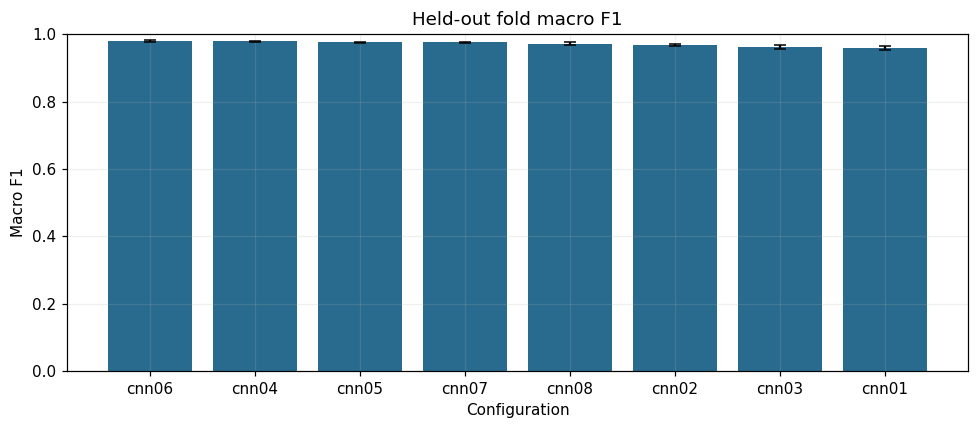

In [49]:
leaderboard = pd.DataFrame(search["leaderboard"])
display(leaderboard[["config_id", "name", "folds", "macro_f1_mean", "macro_f1_std",
                     "injection_precision_mean", "injection_recall_mean", "injection_f1_mean",
                     "false_positive_rate_mean", "roc_auc_mean", "average_precision_mean",
                     "parameter_count", "training_seconds"]])
display(leaderboard.set_index("config_id").filter(regex="_(mean|std)$"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(leaderboard["config_id"], leaderboard["macro_f1_mean"],
       yerr=leaderboard["macro_f1_std"], capsize=4, color="#286b8f")
ax.set(title="Held-out fold macro F1" + (" — smoke demonstration" if SMOKE_MODE else ""),
       xlabel="Configuration", ylabel="Macro F1", ylim=(0, 1))
plt.tight_layout()
plt.show()

## 12. Inspect the leading configuration's learning curves
Compare training and early-stopping losses for the first fold of the leading configuration.
Its vertical line marks the restored epoch. The analysis notebook shows every fold.
The outer held-out fold was not used to choose this epoch.

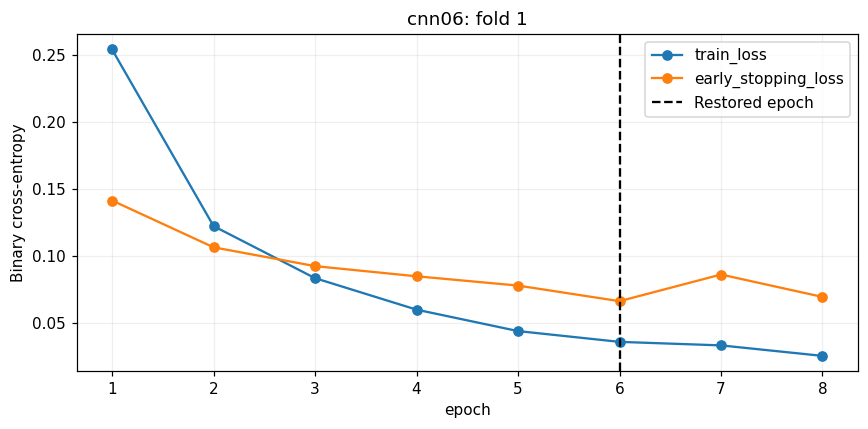

In [50]:
leading_id = leaderboard.iloc[0]["config_id"]
example_run = next(result for result in search["fold_results"] if result["config_id"] == leading_id)
history = pd.DataFrame(example_run["history"])
ax = history.plot(x="epoch", y=["train_loss", "early_stopping_loss"], marker="o", figsize=(8, 4))
ax.axvline(example_run["best_epoch"], color="black", linestyle="--", label="Restored epoch")
ax.set(title=f"{leading_id}: fold {example_run['fold']}", ylabel="Binary cross-entropy")
ax.legend()
plt.tight_layout()
plt.show()

## 13. Retrain the selected configuration on all training rows
After reviewing the fold search, train a fresh model on the complete training split.
Use the **median best epoch count** from the winning configuration's folds. Fit a new
vocabulary on that complete training split. Official validation is still not used.

In smoke mode, this step uses only the small smoke sample; its checkpoint is explicitly
marked as a demonstration. Matching final checkpoints are reused on rerun.

An existing verified selected checkpoint is loaded directly, including after this folder reorganization; no retraining is required.

In [51]:
search = exp.refit_selected(RUN_DIR, DATA_DIR, device=DEVICE)
selected = search["selected"]
print("Selected configuration:", selected["config_id"])
print("Best epochs in its folds:", selected["fold_best_epochs"])
print("Final training epochs:", selected["epochs"])
display(pd.Series(selected["config"], name="Selected settings"))
display(pd.DataFrame(selected["history"]))

Retraining cnn06 on all 18,909 training rows for 7 epoch(s)
Selected configuration: cnn06
Best epochs in its folds: [6, 6, 9, 9, 7]
Final training epochs: 7


config_id                cnn06
name             Kernel size 5
embedding_dim               64
num_filters                256
kernel_size                  5
depth                        1
dropout                    0.3
learning_rate            0.001
weight_decay            0.0001
batch_size                  32
Name: Selected settings, dtype: object

,epoch,train_loss,train_accuracy
0,1,0.228849,0.896769
1,2,0.107198,0.957586
2,3,0.076649,0.971072
3,4,0.050820,0.982125
4,5,0.040165,0.986038
5,6,0.033263,0.988788
6,7,0.032069,0.987942


## 14. Saved outputs and the next part
The experiment folder contains the recipe, original row indices, all fold assignments,
configurations, per-fold checkpoints, histories, predictions, leaderboard, and selected
checkpoint. Hashes guard against resuming unrelated or changed artifacts.

Next open **`cnn_analysis.ipynb`** with the same run mode and experiment name. It loads
these outputs to analyze validation errors and threshold choices. Keep the original
dataset, baseline notebook, and CNN checkpoints as separate historical references.

In [52]:
for name in ("manifest.json", "leaderboard.csv", "leaderboard.json", "selected.json", "selected.pt"):
    print(RUN_DIR / name)
if SMOKE_MODE:
    print("Workflow verified only. Set SMOKE_MODE=False for the real 40-run comparison.")

C:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\artifacts\cnn_experiments\gpu_focused_v1\manifest.json
C:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\artifacts\cnn_experiments\gpu_focused_v1\leaderboard.csv
C:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\artifacts\cnn_experiments\gpu_focused_v1\leaderboard.json
C:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\artifacts\cnn_experiments\gpu_focused_v1\selected.json
C:\Users\ICTAdministrator\DSIT\Machine_Learning\prompt_injection\artifacts\cnn_experiments\gpu_focused_v1\selected.pt
